In [1]:
import cooler
import numpy as np
from cooltools import numutils
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib as mpl

import os

mpl.rcParams['font.size'] = 10
saveFigs = True 
if saveFigs == True:
    figure_path = '../figs/figure1s/count_rows/'
    os.makedirs(figure_path, exist_ok=True)
    # to save inkscape-friendly svgs
    new_rc_params = {'text.usetex': False,
                     "svg.fonttype": 'none'}
    mpl.rcParams.update(new_rc_params)

In [2]:
# load cooler at 50kb resolution from the mcool
cooler_file = '/gladstone/engelhardt/lab/lchumpitaz/hi-c/mcools/4DNFIXP4QG5B.mcool'
resolution = 25000
hic_cooler = cooler.Cooler(cooler_file+'::resolutions/'+str(resolution))

In [3]:
hmm_track = pd.read_csv('../annotations/GM12878_hg38_25kb.tsv', sep='\t')

if (hmm_track['end'].values[0]-hmm_track['start'].values[0]) !=  resolution: 
    raise ValueError('resolution mismatch, check files')

hmm_track.head()

,chrom,start,end,KR,VC,VC_SQRT,weight,GC,E1,E2,...,binary,HMM2,HMM3,HMM3P,HMM4,HMM5,HMM6,HMM7,HMM8,HMM9
0,chr1,0,25000,NaN,0.002548,0.034406,NaN,0.573067,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,chr1,25000,50000,NaN,0.001826,0.029127,NaN,0.430960,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,chr1,50000,75000,NaN,0.019703,0.095678,NaN,0.351400,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,chr1,75000,100000,NaN,0.004713,0.046797,NaN,0.402080,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,chr1,100000,125000,NaN,0.019023,0.094014,NaN,0.371200,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
def chrom_tracks(hmm_track, hic_cooler, chrom):
    chrom_track = hmm_track[hmm_track.chrom==chrom]
    chrom_mat = numutils.adaptive_coarsegrain(hic_cooler.matrix(balance=True).fetch(chrom),
                             hic_cooler.matrix(balance=False).fetch(chrom),
                             cutoff=3, max_levels=8)
    
    return chrom_track, chrom_mat

In [5]:
chrom = 'chr20'
chrom_track, chrom_mat = chrom_tracks(hmm_track, hic_cooler, chrom)

/gladstone/engelhardt/home/lchumpitaz/.local/lib/python3.14/site-packages/cooltools/lib/numutils.py:1376: RuntimeWarning: invalid value encountered in divide
  val_cur = ar_cur / armask_cur


In [6]:
mask = ~chrom_track.E1.isna().values
OE_mat, _, _, _ = numutils.observed_over_expected(chrom_mat, mask)

In [7]:
def distance(a, b):
    d = (a-b)**2
    if len(d.shape)>1:
        return d.mean(axis=1)
    
    return d.mean()

In [8]:
def plot_rows(chrom_track, OE_mat):
    fig = plt.figure(figsize=(15, 10))
    
    mask = ~chrom_track.E1.isna().values
    chrom =  chrom_track.iloc[0].chrom
    res = chrom_track.iloc[0].end - chrom_track.iloc[0].start

    for i in range(5):
        ax = plt.subplot(5, 1, i+1)
        displayed_mat = OE_mat[chrom_track.HMM3P==i ].copy()

    #     print(displayed_mat.shape)

        distances = distance(displayed_mat[:, mask], displayed_mat[0, mask])
        order = np.argsort(distances)
        im = ax.imshow(np.log2(displayed_mat[order]), 
                        cmap='bwr', aspect='auto', vmin=-2.5, vmax=2.5)
        ax.axis('off')
        

    ax.axis('on')
    ax.set_frame_on(False)
    ax.get_yaxis().set_visible(False)
    xticklabels = ((ax.xaxis.get_ticklocs()*res)).astype(int)
    ax.xaxis.set_ticklabels(xticklabels)
    
    cbar_ax = fig.add_axes([1.05, 0.2, 0.025, 0.3])
    cbar = fig.colorbar(im, cax=cbar_ax, shrink = .7, label='Observed/Expected contacts')
    plt.close(fig)        
    
    return fig

In [9]:
fig = plot_rows(chrom_track, OE_mat)

/tmp/ipykernel_1662307/1828594766.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.xaxis.set_ticklabels(xticklabels)


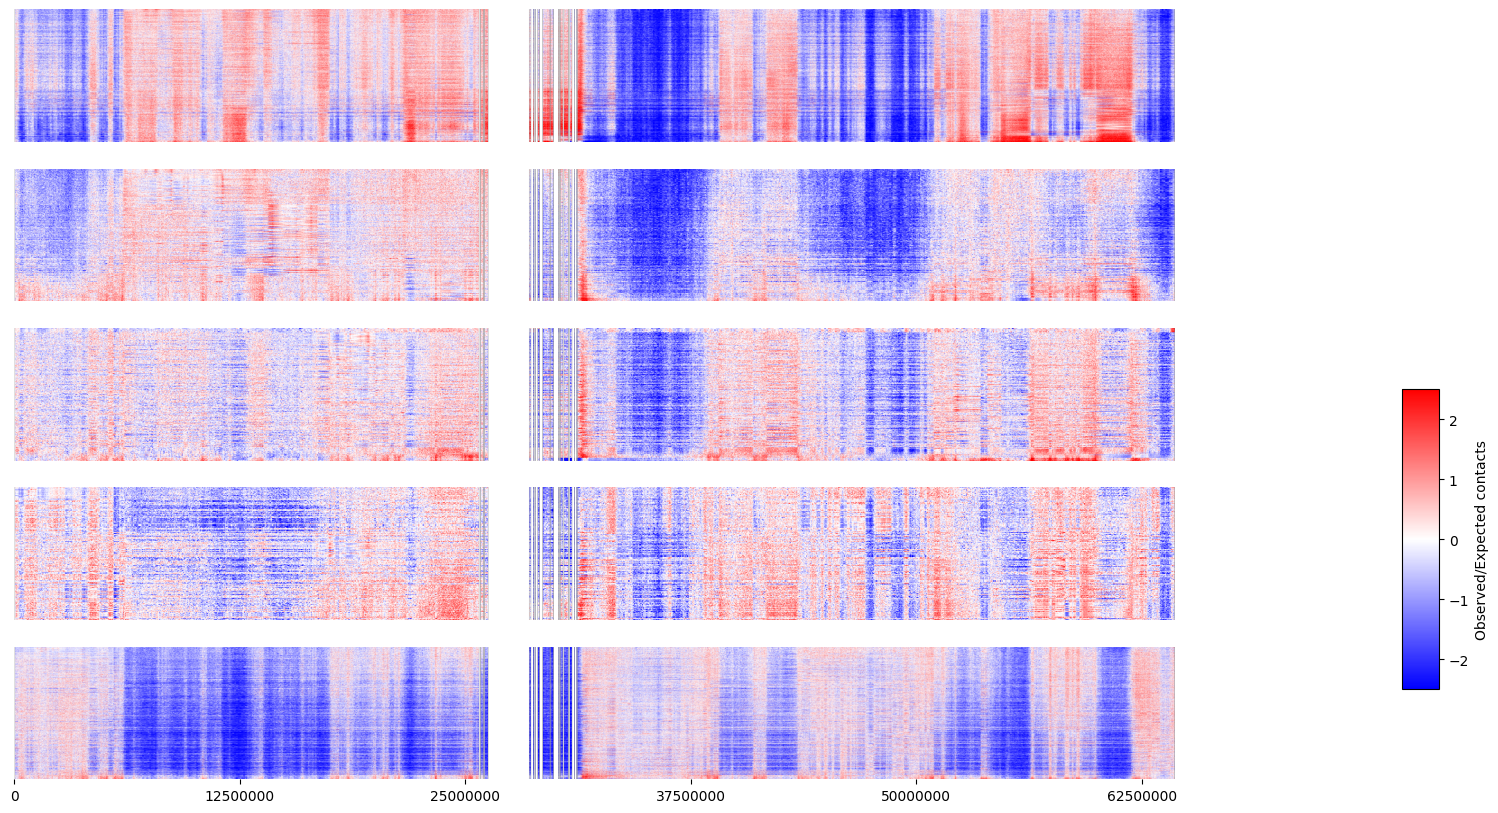

In [10]:
fig

In [11]:
def rows_multichroms(hmm_track, hic_cooler, chroms:list):
    for chrom in chroms:
        chrom_track, chrom_mat = chrom_tracks(hmm_track, hic_cooler, chrom)
        mask = ~chrom_track.E1.isna().values
        OE_mat, _, _, _ = numutils.observed_over_expected(chrom_mat, mask)
        
        fig = plot_rows(chrom_track, OE_mat)
        fig.savefig(figure_path+'intrachromsomal_patterns_'+chrom+'.svg', bbox_inches='tight')
        print("Done with: ", chrom)

In [12]:
chroms = hmm_track.chrom.unique()

In [13]:
chroms[:]

<StringArray>
[ 'chr1',  'chr2',  'chr3',  'chr4',  'chr5',  'chr6',  'chr7',  'chr8',
  'chr9', 'chr10', 'chr11', 'chr12', 'chr13', 'chr14', 'chr15', 'chr16',
 'chr17', 'chr18', 'chr19', 'chr20', 'chr21', 'chr22']
Length: 22, dtype: str

In [14]:
rows_multichroms(hmm_track, hic_cooler, chroms)

/gladstone/engelhardt/home/lchumpitaz/.local/lib/python3.14/site-packages/cooltools/lib/numutils.py:1376: RuntimeWarning: invalid value encountered in divide
  val_cur = ar_cur / armask_cur


/tmp/ipykernel_1662307/1828594766.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.xaxis.set_ticklabels(xticklabels)


Done with:  chr1


/gladstone/engelhardt/home/lchumpitaz/.local/lib/python3.14/site-packages/cooltools/lib/numutils.py:1376: RuntimeWarning: invalid value encountered in divide
  val_cur = ar_cur / armask_cur


/tmp/ipykernel_1662307/1828594766.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.xaxis.set_ticklabels(xticklabels)


Done with:  chr2


... (56 outputs left out)

Done with:  chr21


/gladstone/engelhardt/home/lchumpitaz/.local/lib/python3.14/site-packages/cooltools/lib/numutils.py:1376: RuntimeWarning: invalid value encountered in divide
  val_cur = ar_cur / armask_cur


/tmp/ipykernel_1662307/1828594766.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.xaxis.set_ticklabels(xticklabels)


Done with:  chr22
